In [24]:
# From HW2

library(tidyverse)
# ----------------- function 1, parse the data to useable format
raw <- paste(readLines("../tests/testthat/FemalePlayerCareer.js", warn = FALSE), collapse = "")

rows <- regmatches(raw, gregexpr("\\[[^][]*\\]", raw))[[1]] # find start position and length of a pattern using gregexpr
mat <- do.call(rbind, lapply(rows, function(r)gsub("\"", "", regmatches(r, gregexpr("\"[^\"]*\"", r))[[1]]))) # sub globally all quoted items with non quotes
# ---------------- function 2, get age in right format

# -------------- function 3, get relevant data for plotting. Don't need tournament, surface, opponent
serena <- data.frame(
  date       = as.Date(mat[, 1], "%Y%m%d"),
  tournament = mat[, 2],
  surface    = mat[, 3],
  result     = mat[, 5],
  opponent   = mat[, 12],
  opp_dob    = as.Date(mat[, 17], "%Y%m%d")
)
serena$serena_age <- as.numeric(serena$date - as.Date("1981-09-26")) / 365.25 # include the .25 because there's leap years
serena$opp_age <- as.numeric(serena$date - serena$opp_dob) / 365.25

serena

# Male doesn't work for opp_dob and opp_age, also serena_age is currently hardcoded

        date      tournament surface result                 opponent    opp_dob
1 1995-10-30   Canadian Open  Carpet      L              Anne Miller 1977-01-19
2 1997-03-07    Indian Wells    Hard      L Alexia Dechaume Balleret 1970-05-03
3 1997-08-04 Manhattan Beach    Hard      L              Magui Serna 1979-03-01
  serena_age  opp_age
1   14.09172 18.77618
2   15.44422 26.84463
3   15.85489 18.42847

In [ ]:
url <- "https://www.tennisabstract.com/cgi-bin/wplayer.cgi?p=serenawilliams" # looks like it's not case sensitive
lines <- readLines(url, warn = FALSE)
length(lines) # how many lines the page has
head(lines, 10)

 [1] ""                                                                                                             
 [2] "<html><head>"                                                                                                 
 [3] "<title>Tennis Abstract: erenawilliams WTA Match Results, Splits, and Analysis</title>"                        
 [4] "<link rel=\"stylesheet\" href=\"https://www.tennisabstract.com/blue/style.css\" type=\"text/css\">"           
 [5] "<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/jquery-1.7.1-min.js\"></script>"        
 [6] "<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/jquery.tablesorter.js\"></script>"      
 [7] "<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/jsmatches/serenawilliams.js\"></script>"
 [8] "<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/navbar.js\"></script>"                  
 [9] ""                                                         

In [ ]:
page_text <- paste(lines, collapse = "\n")
nchar(page_text) # total characters
substr(page_text, 1, 500) # collapse all data to 1 string for extraction

[1] "\n<html><head>\n<title>Tennis Abstract: Serena Williams Match Results, Splits, and Analysis</title>\n<link rel=\"stylesheet\" href=\"https://www.tennisabstract.com/blue/style.css\" type=\"text/css\">\n<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/jquery-1.7.1-min.js\"></script>\n<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/jquery.tablesorter.js\"></script>\n<script type=\"text/javascript\" src=\"https://www.tennisabstract.com/navbar.js\"></script>\n\n<script type=\"text/jav"

In [ ]:
regexec(paste0("var ", "dob", " = '?([^';\n]+)"), page_text) # place where DOB is found

[[1]]
[1] 1174 1184
attr(,"match.length")
[1] 18  8


In [14]:
result <- regmatches(page_text, regexec(paste0("var ", "dob", " = '?([^';\n]+)"), page_text))
result # cut out actual value

[[1]]
[1] "var dob = 19810926" "19810926"          


In [19]:
tolower(gsub(" ", "", "Serena Williams"))

[1] "serenawilliams"

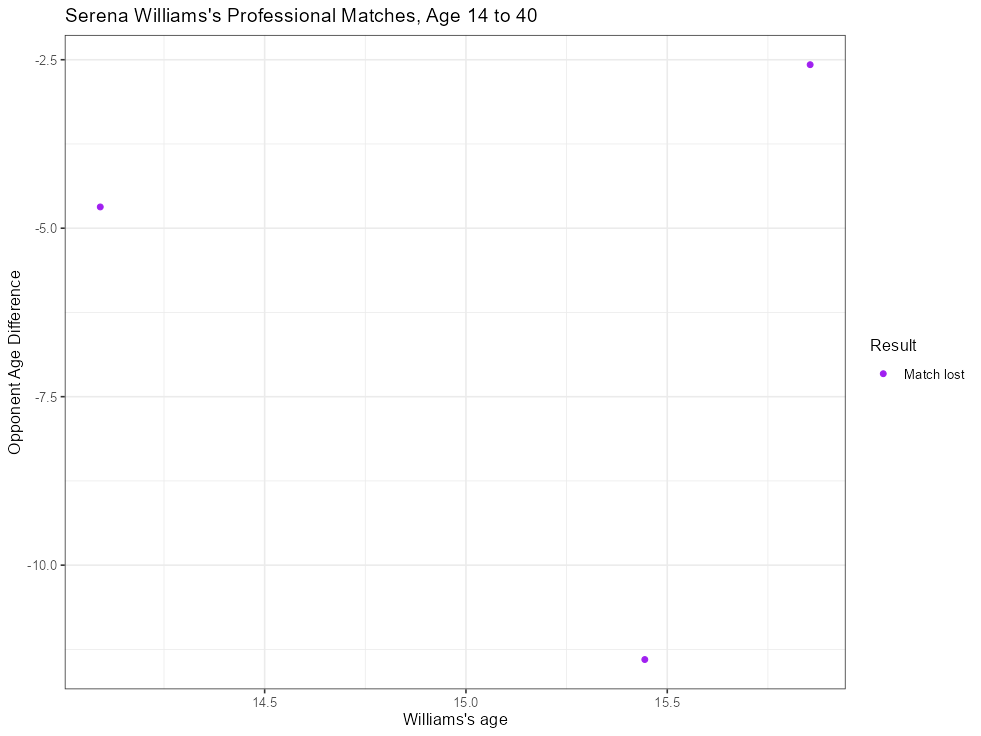

In [25]:
dat <- serena

p <- ggplot2::ggplot(dat, aes(x = serena_age, y = serena_age - opp_age, color = result)) + 
  ggplot2::geom_point() +
  ggplot2::scale_color_manual(
    name   = "Result",
    values = c("W" = "skyblue", "L" = "purple"),
    labels = c("L" = "Match lost", "W" = "Match Williams won")
  ) +
  ggplot2::labs(title = "Serena Williams's Professional Matches, Age 14 to 40", 
      x = "Williams's age", y = "Opponent Age Difference") +
  ggplot2::theme_bw()

p